In [2]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

from fat_tails import (
    get_degrees,
    plot_histogram,
    plot_loglog_histogram,
    plot_log_binned_histogram,
    plot_survival_function,
    alpha_regression,
    plot_alpha_regression,
    mle_alpha,
)

## 4.0


### 4.0.1-3 Import the data, draw their histogram. Correct the scale of the plot’s axes to double logarithmic. Apply logarithmic binning as well.


nodes: 1870
edges: 2277
min degree: 1
max degree: 56


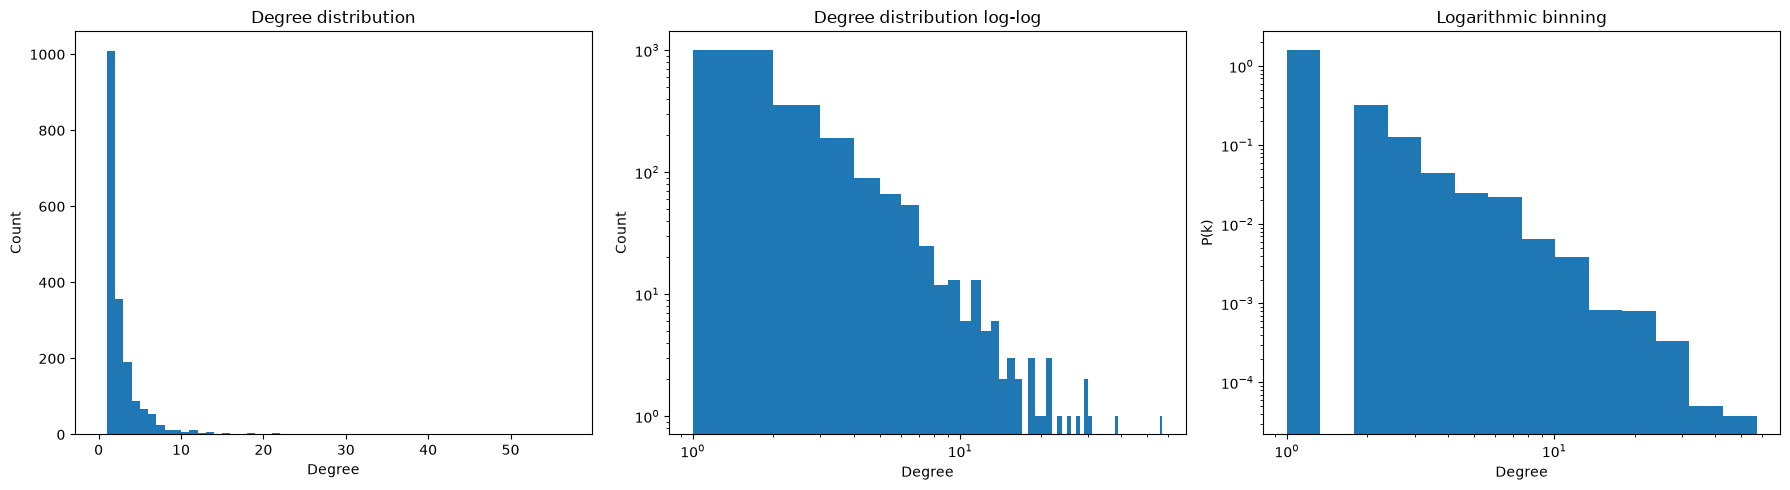

In [ ]:
edges = pd.read_csv("data/yeast.edges", sep=" ")
G = nx.from_pandas_edgelist(edges, "n1", "n2")
degrees = get_degrees(G)
print("nodes:", G.number_of_nodes())
print("edges:", G.number_of_edges())
print("min degree:", min(degrees))
print("max degree:", max(degrees))

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_histogram(G, axes[0])
plot_loglog_histogram(G, axes[1])
plot_log_binned_histogram(G, ax=axes[2])
plt.tight_layout()
plt.show()

### 4.0.4 Compute and draw the survival function.

The survival function $S(k) = P(K \ge k) = 1 - P(K < k)$ is the fraction of nodes with degree at least $k$.
It starts at $S(1) = 1$ (every node has degree at least 1) and goes down as $k$ grows.


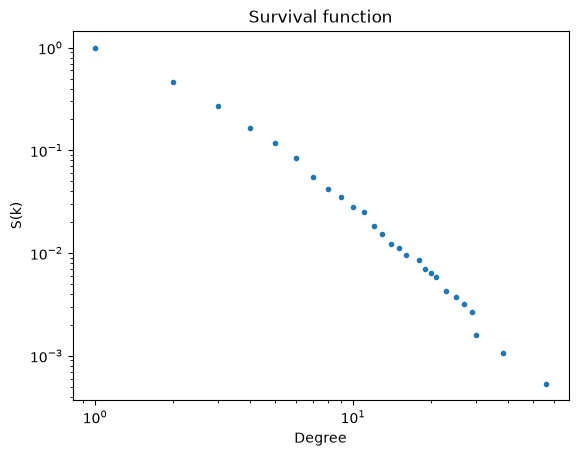

In [52]:
plot_survival_function(G)
plt.show()

### 4.0.5 Which chart is the most readable? Which is most robust for the noise?

- **Histogram** – the least readable. More than half of the nodes have degree 1, so almost everything is in the first few bars and the rest of the plot is empty.
- **Log-log histogram** – the beginning is clear, but above degree ~10 most degrees appear only 1–3 times or not at all. 
- **Logarithmic binning** – the most readable. The bins get wider for larger degrees, so each bin collects enough nodes and the bars go down along a clear line. Downside: the result depends on the number of bins, and some narrow bins at small degrees can be empty, because degrees are whole numbers (the gap next to the first bar).
- **Survival function** – the most robust to noise. There are no bins, and each point counts all nodes with degree $\ge k$, so random ups and downs average out and the curve is smooth.


### 4.0.6 Use the linear regression to the previous plots to determine the parameter α estimator.

On log-log axes a power law is a straight line: $\log P(k) = -\alpha \log k + c$.
We fit a line to each plot: for the two histograms $\alpha = -\text{slope}$, for the survival function $\alpha = 1 - \text{slope}$.
We use all degrees ($x_{min} = 1$), because for this network the plots look roughly straight from the start.


loglog: alpha = 2.11
log_binning: alpha = 2.80
survival: alpha = 2.98


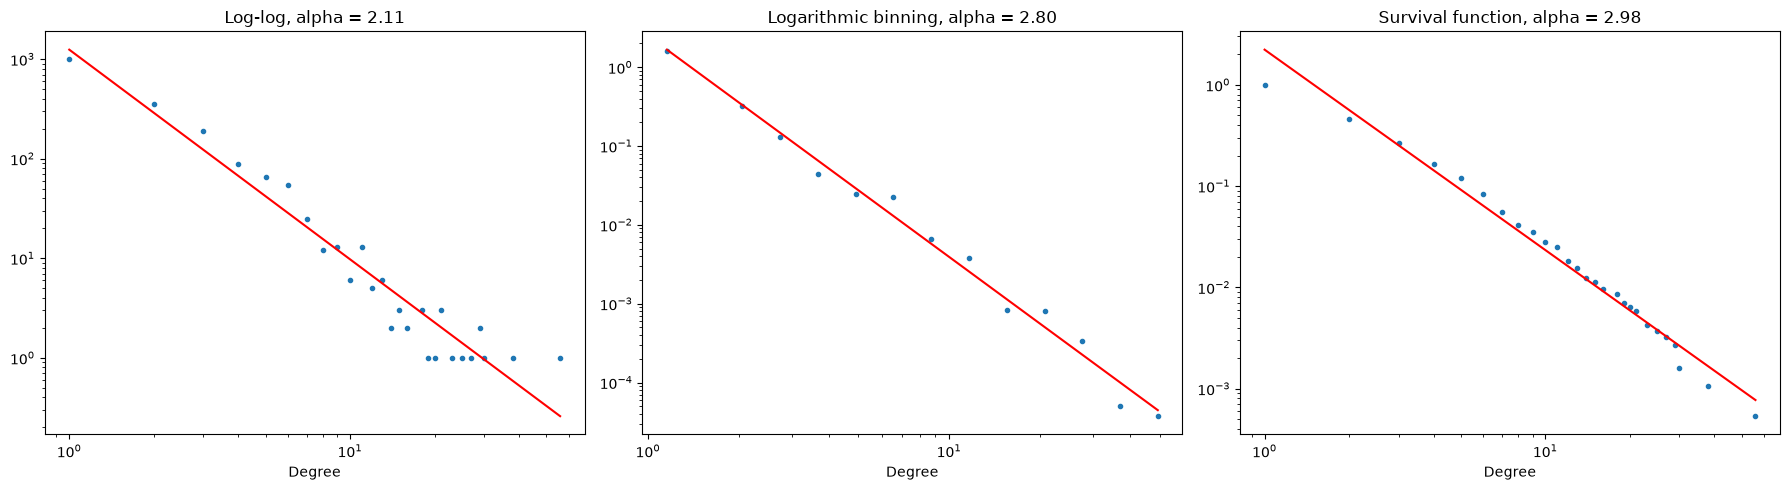

In [53]:
x_min = 1
for method, alpha in alpha_regression(G, x_min=x_min).items():
    print(f"{method}: alpha = {alpha:.2f}")

plot_alpha_regression(G, x_min=x_min)
plt.show()

### 4.0.7 Compute (formula and value for our data) MLE estimator for α with a known xmin.

$$\hat{\alpha} = 1 + n \left(\sum_{i=1}^{n} \ln\frac{x_i}{x_{min}}\right)^{-1}$$
dla $x_i > x_{min}$


In [54]:
mle_alpha(G, x_min=1)

np.float64(2.8177308179229126)

### 4.0.8 How will the result change if we do not know xmin?

The MLE formula needs $x_{min}$. If we don't know it, we have to choose it ourselves, and the estimation of $\alpha$ depends on that choice.


x_min =  1: alpha = 2.82, nodes used = 1870
x_min =  2: alpha = 2.99, nodes used = 860
x_min =  3: alpha = 3.20, nodes used = 503
x_min =  4: alpha = 3.25, nodes used = 312
x_min =  5: alpha = 3.50, nodes used = 223
x_min =  6: alpha = 3.59, nodes used = 157
x_min =  7: alpha = 3.31, nodes used = 103
x_min =  8: alpha = 3.28, nodes used = 78
x_min =  9: alpha = 3.49, nodes used = 66
x_min = 10: alpha = 3.54, nodes used = 53
x_min = 11: alpha = 3.86, nodes used = 47
x_min = 12: alpha = 3.52, nodes used = 34
x_min = 13: alpha = 3.60, nodes used = 29
x_min = 14: alpha = 3.44, nodes used = 23
x_min = 15: alpha = 3.63, nodes used = 21
x_min = 16: alpha = 3.63, nodes used = 18
x_min = 17: alpha = 3.73, nodes used = 16
x_min = 18: alpha = 4.23, nodes used = 16
x_min = 19: alpha = 4.06, nodes used = 13
x_min = 20: alpha = 4.31, nodes used = 12


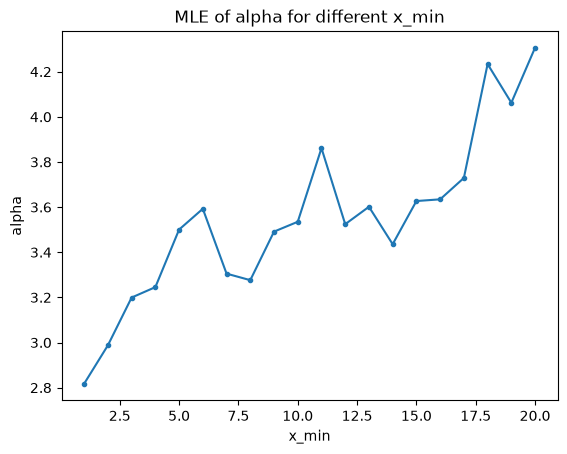

In [ ]:
# kolmogorow smirnoff almo mle xmin
x_mins = range(1, 21)
alphas = [mle_alpha(G, x) for x in x_mins]
tail_sizes = [sum(degrees >= x) for x in x_mins]

for x, alpha, n in zip(x_mins, alphas, tail_sizes):
    print(f"x_min = {x:2d}: alpha = {alpha:.2f}, nodes used = {n}")

plt.plot(x_mins, alphas, marker=".")
plt.xlabel("x_min")
plt.ylabel("alpha")
plt.title("MLE of alpha for different x_min")
plt.show()

The estimate grows with $x_{min}$

Too small $x_{min}$ – many nodes, so the estimate is stable, but it also uses small degrees, which do not follow the power law exactly (the survival function bends a little at the start). This gives a smaller $\alpha$.

Too large $x_{min}$ – only a few nodes are left, so the estimate is noisy.

So without a known $x_{min}$, $\alpha$ is less certain and it depends on our choice of $x_{min}$.


## 4.3 Average nearest-neighbor degree

For each node, we calculate the mean degree of its neighbors, then average this value over nodes with the same degree $k$.


Degree assortativity coef: Yeast -0.15677830525143321
Degree assortativity coef: Facebook 0.06357722918564943
Degree assortativity coef: Football 0.16244224957444287


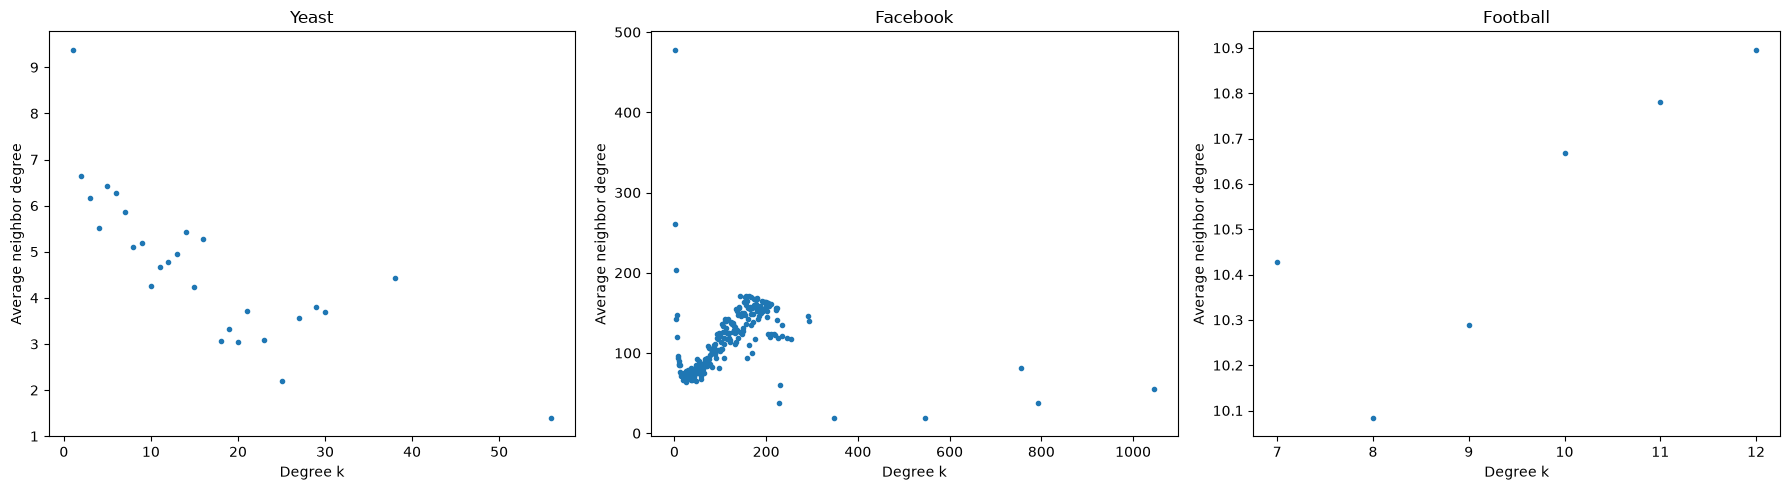

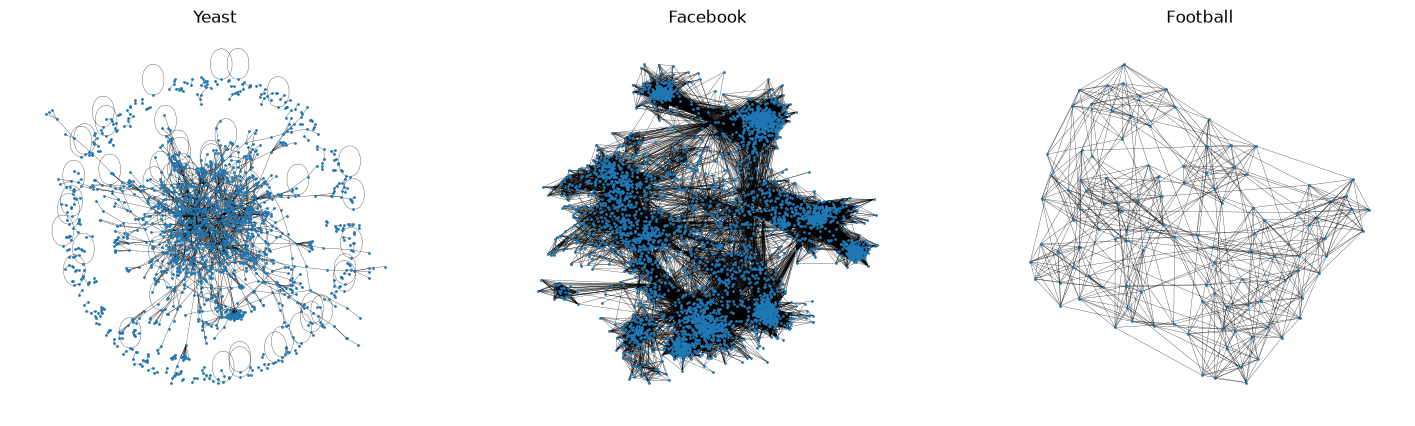

In [5]:
edges = pd.read_csv("data/yeast.edges", sep=" ")
G_yeast = nx.from_pandas_edgelist(edges, "n1", "n2")
edges = pd.read_csv("data/facebook.txt", sep=" ")
G_facebook = nx.from_pandas_edgelist(edges, "source", "target")
G_football = nx.read_gml("data/football.gml")

graphs = [G_yeast, G_facebook, G_football]
names = ["Yeast", "Facebook", "Football"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i in range(3):
    knn = nx.average_degree_connectivity(graphs[i])
    axes[i].plot(sorted(knn), [knn[k] for k in sorted(knn)], ".")
    axes[i].set_title(names[i])
    axes[i].set_xlabel("Degree k")
    axes[i].set_ylabel("Average neighbor degree")
    print(
        "Degree assortativity coef:",
        names[i],
        nx.degree_assortativity_coefficient(graphs[i]),
    )
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for G, name, ax in zip(graphs, names, axes):
    nx.draw(G, ax=ax, node_size=1, width=0.2)
    ax.set_title(name)
plt.show()

## 4.4 Random edge switching

For each of the three networks from 4.3, we make 10 successful swaps per edge on a copy of the graph. The fixed seed makes the result reproducible.A swap replaces two edges while preserving every node's degree. Connectivity is not preserved by this procedure.


Yeast degrees preserved: True
Degree assortativity coef: Yeast -0.02405818499297729
Facebook degrees preserved: True
Degree assortativity coef: Facebook -0.04445891038263868
Football degrees preserved: True
Degree assortativity coef: Football -0.03630026747565207


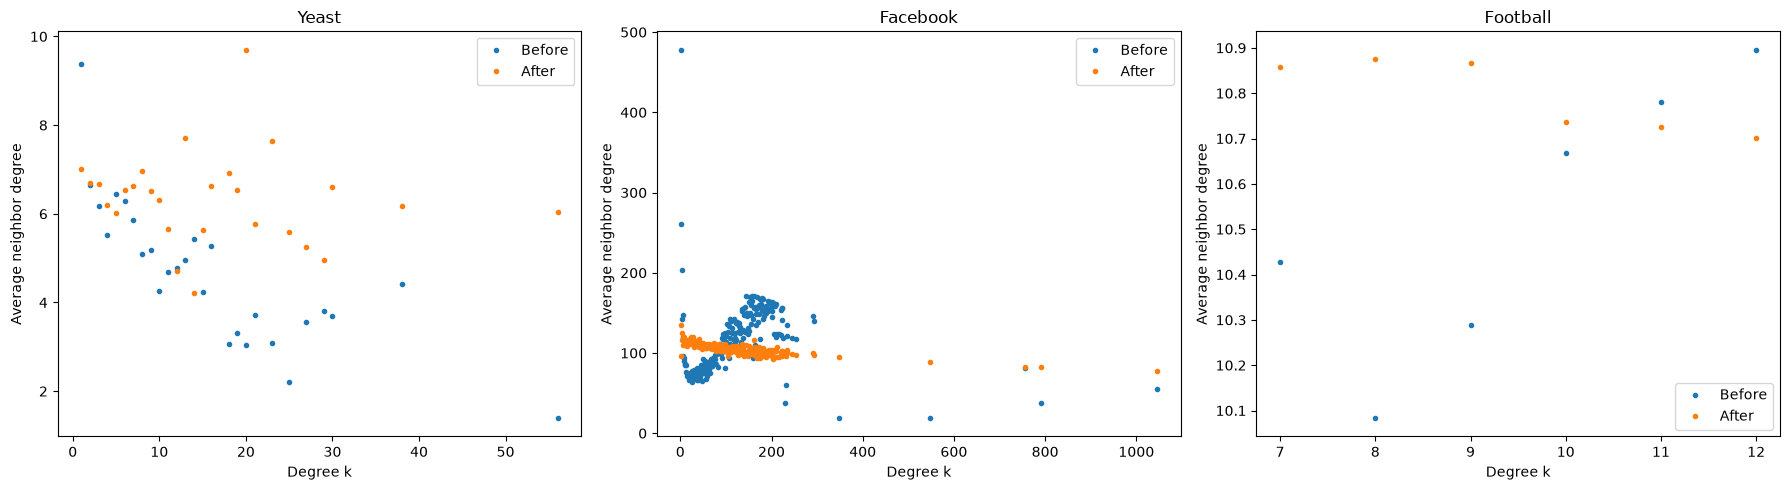

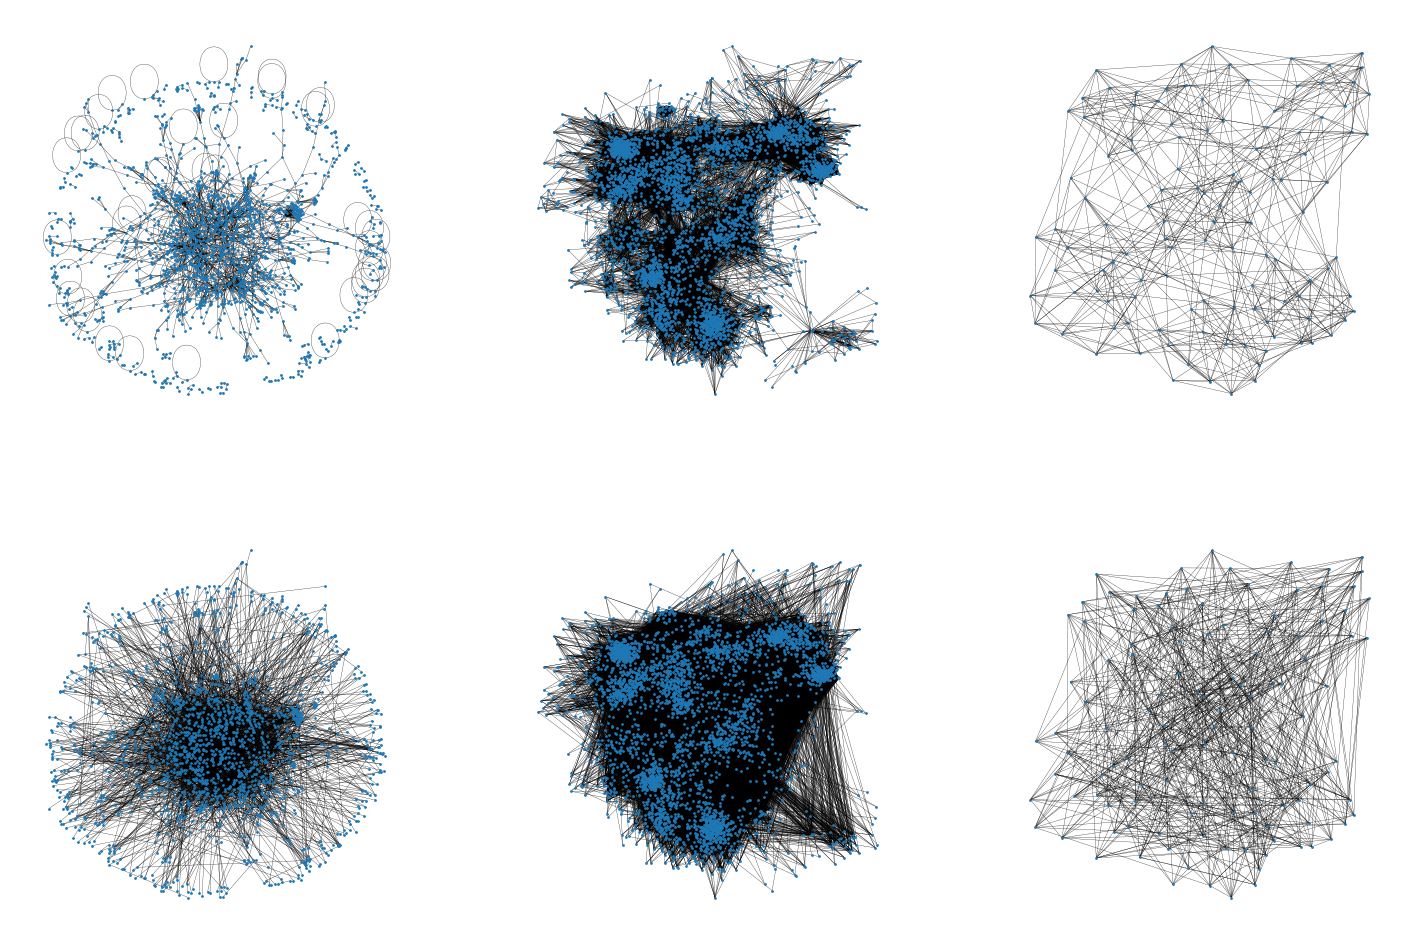

In [8]:
random_graphs = []
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i in range(3):
    G_random = graphs[i].copy()
    m = G_random.number_of_edges()
    nx.double_edge_swap(G_random, nswap=10 * m, max_tries=100 * m, seed=2)
    random_graphs.append(G_random)

    knn = nx.average_degree_connectivity(graphs[i])
    knn_random = nx.average_degree_connectivity(G_random)
    axes[i].plot(sorted(knn), [knn[k] for k in sorted(knn)], ".", label="Before")
    axes[i].plot(
        sorted(knn_random),
        [knn_random[k] for k in sorted(knn_random)],
        ".",
        label="After",
    )
    axes[i].set_title(names[i])
    axes[i].set_xlabel("Degree k")
    axes[i].set_ylabel("Average neighbor degree")
    axes[i].legend()
    print(
        names[i],
        "degrees preserved:",
        dict(graphs[i].degree()) == dict(G_random.degree()),
    )
    print(
        "Degree assortativity coef:",
        names[i],
        nx.degree_assortativity_coefficient(G_random),
    )
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for i, (G, H) in enumerate(zip(graphs, random_graphs)):
    pos = nx.spring_layout(G, seed=2)
    for ax, g in zip(axes[:, i], (G, H)):
        nx.draw(g, pos, ax=ax, node_size=1, width=0.2)
plt.show()

## 4.6 Degree correlation before and after edge switching

Calculation of correlation coefficient between the degrees at the two ends of an edge (degree assortativity). Positive values mean similar degrees tend to connect, negative values mean different degrees tend to connect, and values near zero indicate weak linear correlation.

$$
r =
\frac{
\frac{1}{M}\sum_{i=1}^{M} j_i k_i
-
\left[\frac{1}{2M}\sum_{i=1}^{M}(j_i+k_i)\right]^2
}{
\frac{1}{2M}\sum_{i=1}^{M}(j_i^2+k_i^2)
-
\left[\frac{1}{2M}\sum_{i=1}^{M}(j_i+k_i)\right]^2
}
$$


In [ ]:
def degree_correlation(G):
    M = G.number_of_edges()
    degrees = dict(G.degree())

    sum_jk = 0
    sum_j_plus_k = 0
    sum_j2_plus_k2 = 0

    for u, v in G.edges():
        j = degrees[u]
        k = degrees[v]
        sum_jk += j * k
        sum_j_plus_k += j + k
        sum_j2_plus_k2 += j**2 + k**2

    num = sum_jk / M - (sum_j_plus_k / (2 * M)) ** 2
    den = sum_j2_plus_k2 / (2 * M) - (sum_j_plus_k / (2 * M)) ** 2

    r = num / den
    return r

In [73]:
for i in range(3):
    print(
        names[i],
        "before:",
        degree_correlation(graphs[i]),
        "after:",
        degree_correlation(random_graphs[i]),
    )

Yeast before: -0.15234681815248388 after: -0.024058184992977245
Facebook before: 0.06357722918564915 after: -0.04445891038263846
Football before: 0.16244224957446363 after: -0.03630026747565422


## 4.7 Erdős numbers of Nobel laureates and Fields medalists

- [Nobel laureates](https://sites.google.com/oakland.edu/grossman/home/the-erdoes-number-project/some-famous-people-with-finite-erdoes-numbers/nobel-prize-winners)
- [Fields medalists](https://sites.google.com/oakland.edu/grossman/home/the-erdoes-number-project/some-famous-people-with-finite-erdoes-numbers/fields-medal-winners)


Nobel laureates known: 320 unknown: 3
Mean: 5.21 median: 5.0


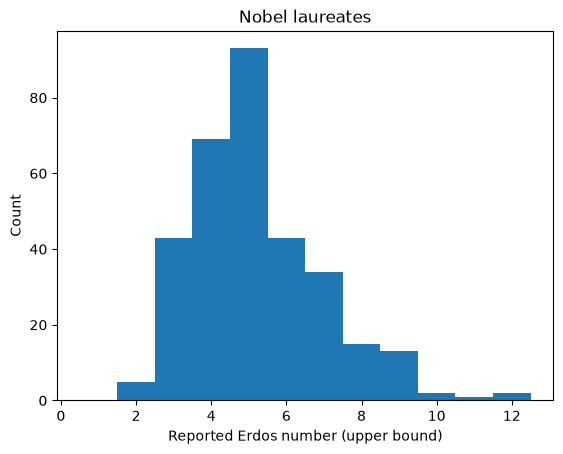

Fields medalists known: 68 unknown: 0
Mean: 3.16 median: 3.0


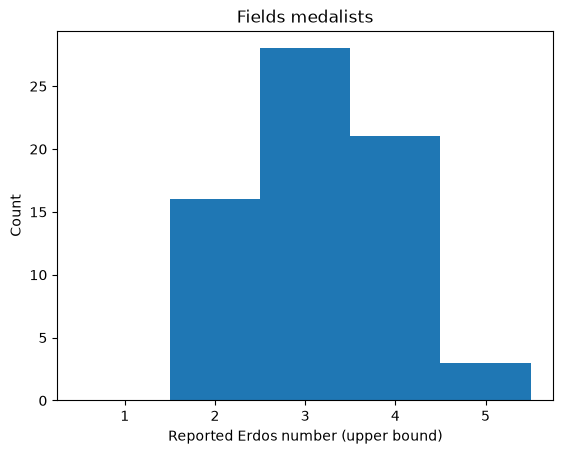

In [60]:
nobel = pd.read_csv("data/nobel_erdos.csv").drop_duplicates("name")
fields = pd.read_csv("data/fields_erdos.csv").drop_duplicates("name")
for title, data in [("Nobel laureates", nobel), ("Fields medalists", fields)]:
    values = data["erdos"].dropna().astype(int)
    print(title, "known:", len(values), "unknown:", data["erdos"].isna().sum())
    print("Mean:", round(values.mean(), 2), "median:", values.median())
    plt.hist(values, bins=[k - 0.5 for k in range(1, values.max() + 2)])
    plt.title(title)
    plt.xlabel("Reported Erdos number (upper bound)")
    plt.ylabel("Count")
    plt.show()